In [1]:
from google.colab import files

uploaded = files.upload()

Saving blockchain_attack_dataset.csv to blockchain_attack_dataset.csv


In [2]:
import pandas as pd

df = pd.read_csv('blockchain_attack_dataset.csv')

df.head()

,Unnamed: 0,Index,Address,FLAG,Avg min between sent tnx,Avg min between received tnx,Time Diff between first and last (Mins),Sent tnx,Received Tnx,Number of Created Contracts,...,ERC20 min val sent,ERC20 max val sent,ERC20 avg val sent,ERC20 min val sent contract,ERC20 max val sent contract,ERC20 avg val sent contract,ERC20 uniq sent token name,ERC20 uniq rec token name,ERC20 most sent token type,ERC20_most_rec_token_type
0,0,1,0x00009277775ac7d0d59eaad8fee3d10ac6c805e8,0,844.26,1093.71,704785.63,721,89,0,...,0.000000,1.683100e+07,271779.920000,0.0,0.0,0.0,39.0,57.0,Cofoundit,Numeraire
1,1,2,0x0002b44ddb1476db43c868bd494422ee4c136fed,0,12709.07,2958.44,1218216.73,94,8,0,...,2.260809,2.260809e+00,2.260809,0.0,0.0,0.0,1.0,7.0,Livepeer Token,Livepeer Token
2,2,3,0x0002bda54cb772d040f779e88eb453cac0daa244,0,246194.54,2434.02,516729.30,2,10,0,...,0.000000,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,8.0,NaN,XENON
3,3,4,0x00038e6ba2fd5c09aedb96697c8d7b8fa6632e5e,0,10219.60,15785.09,397555.90,25,9,0,...,100.000000,9.029231e+03,3804.076893,0.0,0.0,0.0,1.0,11.0,Raiden,XENON
4,4,5,0x00062d1dd1afb6fb02540ddad9cdebfe568e0d89,0,36.61,10707.77,382472.42,4598,20,1,...,0.000000,4.500000e+04,13726.659220,0.0,0.0,0.0,6.0,27.0,StatusNetwork,EOS


In [3]:
df.shape


(9841, 51)

In [4]:
df.columns


Index(['Unnamed: 0', 'Index', 'Address', 'FLAG', 'Avg min between sent tnx',
       'Avg min between received tnx',
       'Time Diff between first and last (Mins)', 'Sent tnx', 'Received Tnx',
       'Number of Created Contracts', 'Unique Received From Addresses',
       'Unique Sent To Addresses', 'min value received', 'max value received ',
       'avg val received', 'min val sent', 'max val sent', 'avg val sent',
       'min value sent to contract', 'max val sent to contract',
       'avg value sent to contract',
       'total transactions (including tnx to create contract',
       'total Ether sent', 'total ether received',
       'total ether sent contracts', 'total ether balance',
       ' Total ERC20 tnxs', ' ERC20 total Ether received',
       ' ERC20 total ether sent', ' ERC20 total Ether sent contract',
       ' ERC20 uniq sent addr', ' ERC20 uniq rec addr',
       ' ERC20 uniq sent addr.1', ' ERC20 uniq rec contract addr',
       ' ERC20 avg time between sent tnx', ' ERC20 

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9841 entries, 0 to 9840
Data columns (total 51 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   Unnamed: 0                                            9841 non-null   int64  
 1   Index                                                 9841 non-null   int64  
 2   Address                                               9841 non-null   object 
 3   FLAG                                                  9841 non-null   int64  
 4   Avg min between sent tnx                              9841 non-null   float64
 5   Avg min between received tnx                          9841 non-null   float64
 6   Time Diff between first and last (Mins)               9841 non-null   float64
 7   Sent tnx                                              9841 non-null   int64  
 8   Received Tnx                                          9841

In [6]:
df.isnull().sum().sort_values(ascending=False)

,0
ERC20 most sent token type,2697
ERC20_most_rec_token_type,871
ERC20 avg val sent,829
ERC20 total Ether received,829
ERC20 total ether sent,829
ERC20 avg time between rec tnx,829
ERC20 avg time between rec 2 tnx,829
ERC20 max val rec,829
ERC20 avg val rec,829
ERC20 avg time between contract tnx,829


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.drop(['Unnamed: 0','Index','Address'],
        axis=1,
        inplace=True)

In [10]:
df.shape

(9841, 48)

In [11]:
df['FLAG'].value_counts()

,count
FLAG,
0,7662
1,2179


In [12]:
df['FLAG'].value_counts(normalize=True)*100

,proportion
FLAG,
0,77.857941
1,22.142059


In [13]:
df.dtypes

,0
FLAG,int64
Avg min between sent tnx,float64
Avg min between received tnx,float64
Time Diff between first and last (Mins),float64
Sent tnx,int64
Received Tnx,int64
Number of Created Contracts,int64
Unique Received From Addresses,int64
Unique Sent To Addresses,int64
min value received,float64


In [14]:
df.select_dtypes(include=['object']).columns

Index([' ERC20 most sent token type', ' ERC20_most_rec_token_type'], dtype='object')

In [15]:
df.describe()

,FLAG,Avg min between sent tnx,Avg min between received tnx,Time Diff between first and last (Mins),Sent tnx,Received Tnx,Number of Created Contracts,Unique Received From Addresses,Unique Sent To Addresses,min value received,...,ERC20 max val rec,ERC20 avg val rec,ERC20 min val sent,ERC20 max val sent,ERC20 avg val sent,ERC20 min val sent contract,ERC20 max val sent contract,ERC20 avg val sent contract,ERC20 uniq sent token name,ERC20 uniq rec token name
count,9841.000000,9841.000000,9841.000000,9.841000e+03,9841.000000,9841.000000,9841.000000,9841.000000,9841.000000,9841.000000,...,9.012000e+03,9.012000e+03,9.012000e+03,9.012000e+03,9.012000e+03,9012.0,9012.0,9012.0,9012.000000,9012.000000
mean,0.221421,5086.878721,8004.851184,2.183333e+05,115.931714,163.700945,3.729702,30.360939,25.840159,43.845153,...,1.252524e+08,4.346203e+06,1.174126e+04,1.303594e+07,6.318389e+06,0.0,0.0,0.0,1.384931,4.826676
std,0.415224,21486.549974,23081.714801,3.229379e+05,757.226361,940.836550,141.445583,298.621112,263.820410,325.929139,...,1.053741e+10,2.141192e+08,1.053567e+06,1.179905e+09,5.914764e+08,0.0,0.0,0.0,6.735121,16.678607
min,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.000000,0.000000
25%,0.000000,0.000000,0.000000,3.169300e+02,1.000000,1.000000,0.000000,1.000000,1.000000,0.001000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.000000,0.000000
50%,0.000000,17.340000,509.770000,4.663703e+04,3.000000,4.000000,0.000000,2.000000,2.000000,0.095856,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.000000,1.000000
75%,0.000000,565.470000,5480.390000,3.040710e+05,11.000000,27.000000,0.000000,5.000000,3.000000,2.000000,...,9.900000e+01,2.946467e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.000000,2.000000
max,1.000000,430287.670000,482175.490000,1.954861e+06,10000.000000,10000.000000,9995.000000,9999.000000,9287.000000,10000.000000,...,1.000000e+12,1.724181e+10,1.000000e+08,1.120000e+11,5.614756e+10,0.0,0.0,0.0,213.000000,737.000000


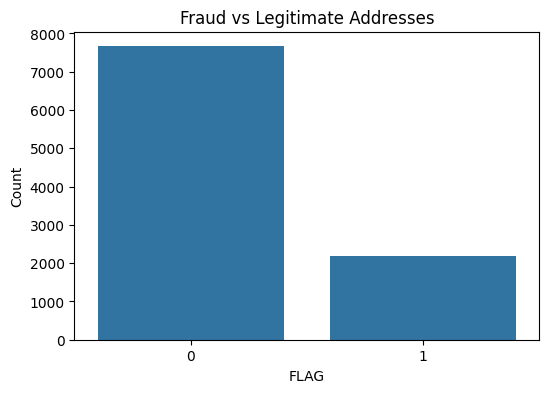

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(x='FLAG', data=df)

plt.title('Fraud vs Legitimate Addresses')
plt.xlabel('FLAG')
plt.ylabel('Count')

plt.show()

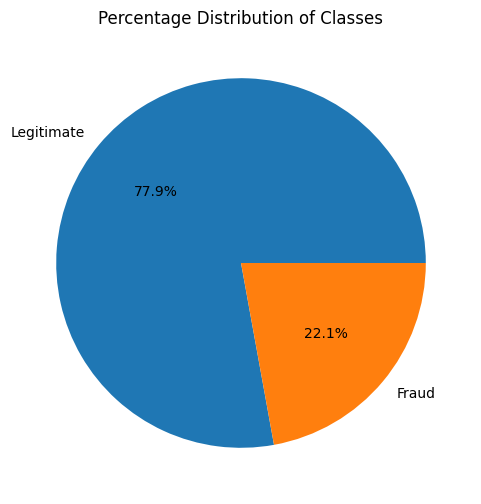

In [17]:
flag_counts = df['FLAG'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    flag_counts,
    labels=['Legitimate','Fraud'],
    autopct='%1.1f%%'
)

plt.title('Percentage Distribution of Classes')

plt.show()

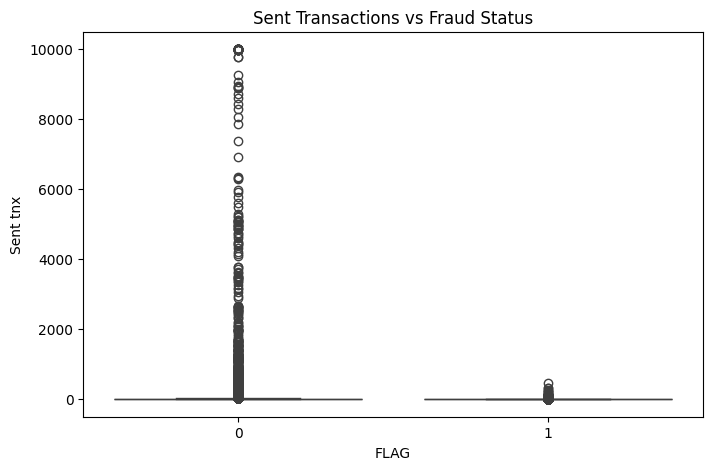

In [18]:
plt.figure(figsize=(8,5))

sns.boxplot(x='FLAG',
            y='Sent tnx',
            data=df)

plt.title('Sent Transactions vs Fraud Status')

plt.show()

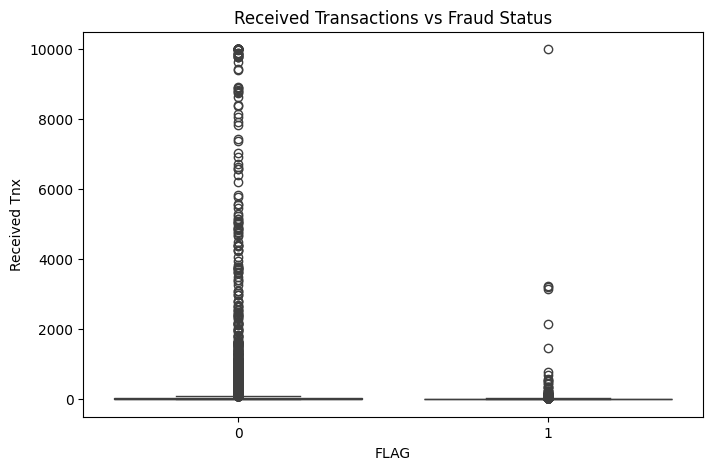

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(x='FLAG',
            y='Received Tnx',
            data=df)

plt.title('Received Transactions vs Fraud Status')

plt.show()

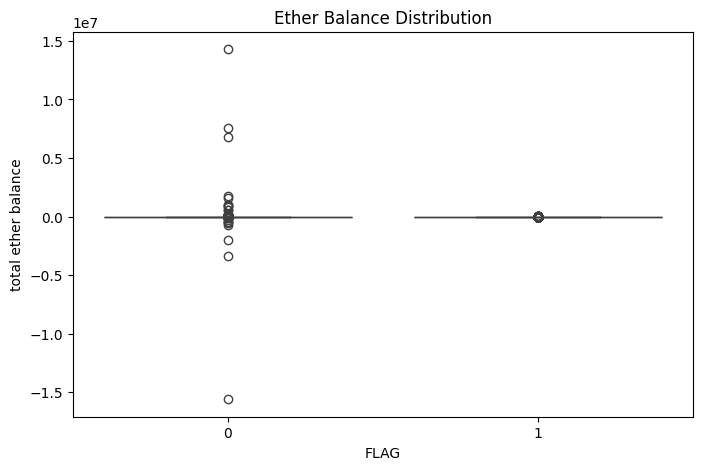

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(x='FLAG',
            y='total ether balance',
            data=df)

plt.title('Ether Balance Distribution')

plt.show()

In [21]:
numeric_df = df.select_dtypes(include=['int64','float64'])

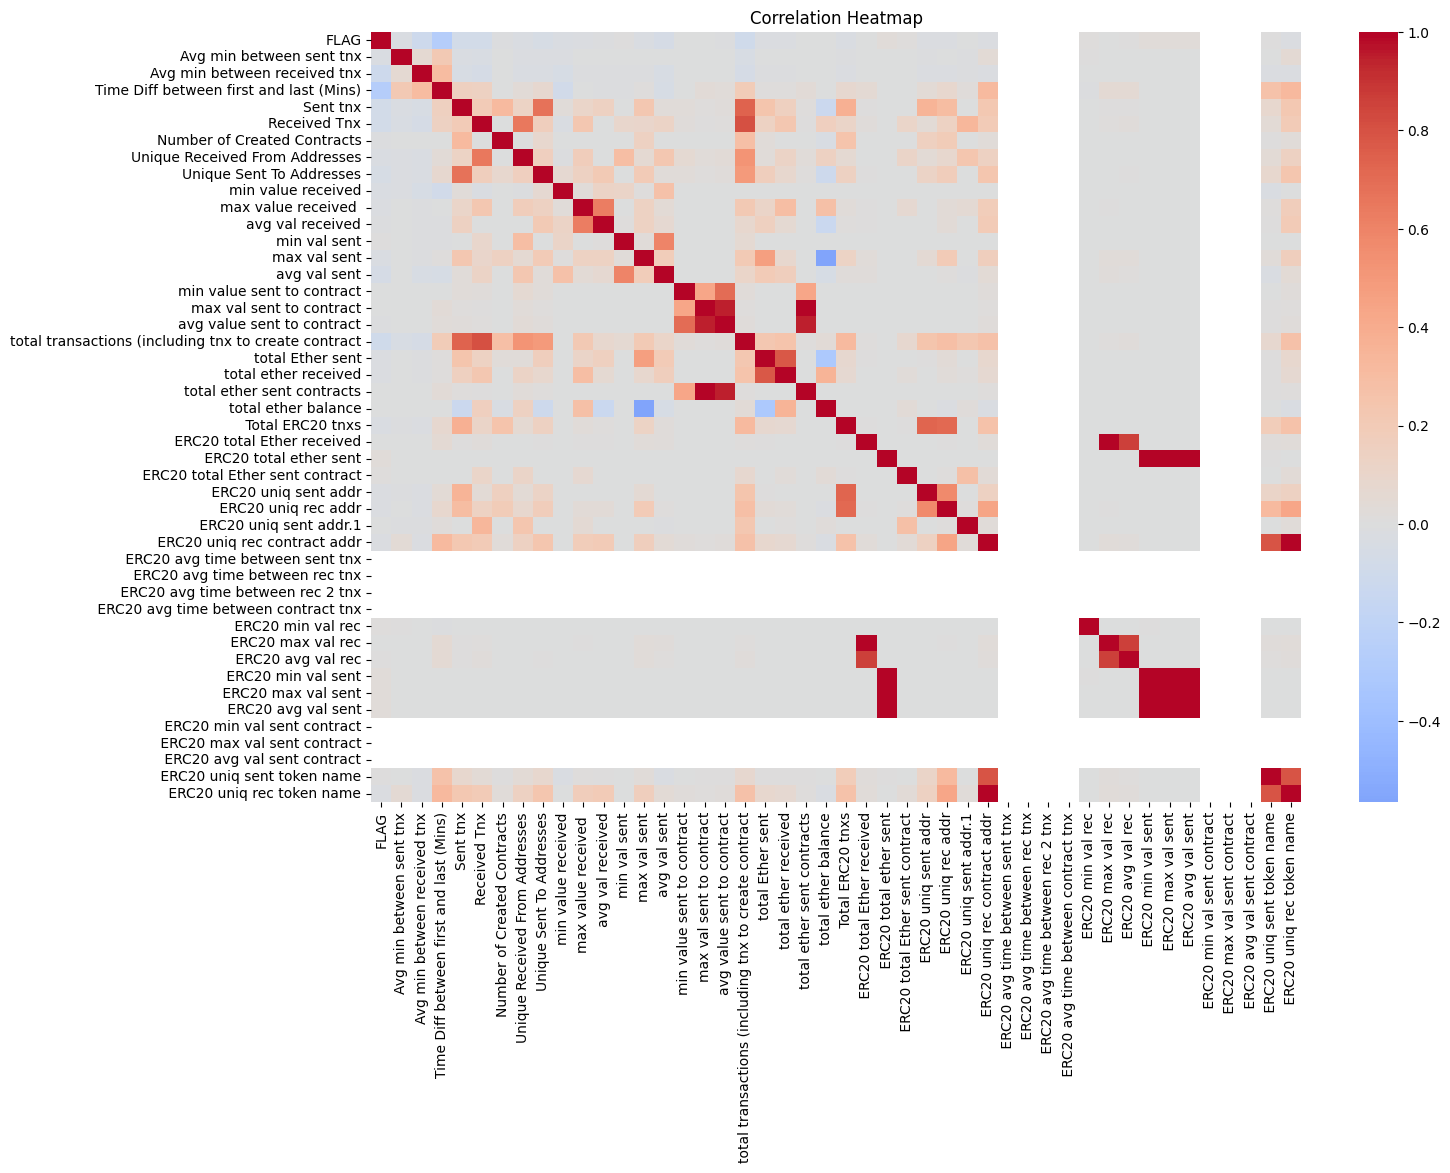

In [22]:
plt.figure(figsize=(15,10))

corr = numeric_df.corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')

plt.show()

In [23]:
corr_with_flag = numeric_df.corr()['FLAG'].sort_values(ascending=False)

print(corr_with_flag.head(15))

FLAG                                1.000000
 ERC20 min val sent                 0.025364
 ERC20 avg val sent                 0.025044
 ERC20 max val sent                 0.025038
 ERC20 total ether sent             0.024762
 ERC20 total Ether sent contract    0.013514
 ERC20 min val rec                  0.011163
 ERC20 uniq sent token name         0.009249
 ERC20 avg val rec                  0.007881
min val sent                        0.006626
 ERC20 uniq sent addr.1            -0.003047
total ether balance                -0.003229
 ERC20 max val rec                 -0.004313
 ERC20 total Ether received        -0.004475
min value sent to contract         -0.007213
Name: FLAG, dtype: float64


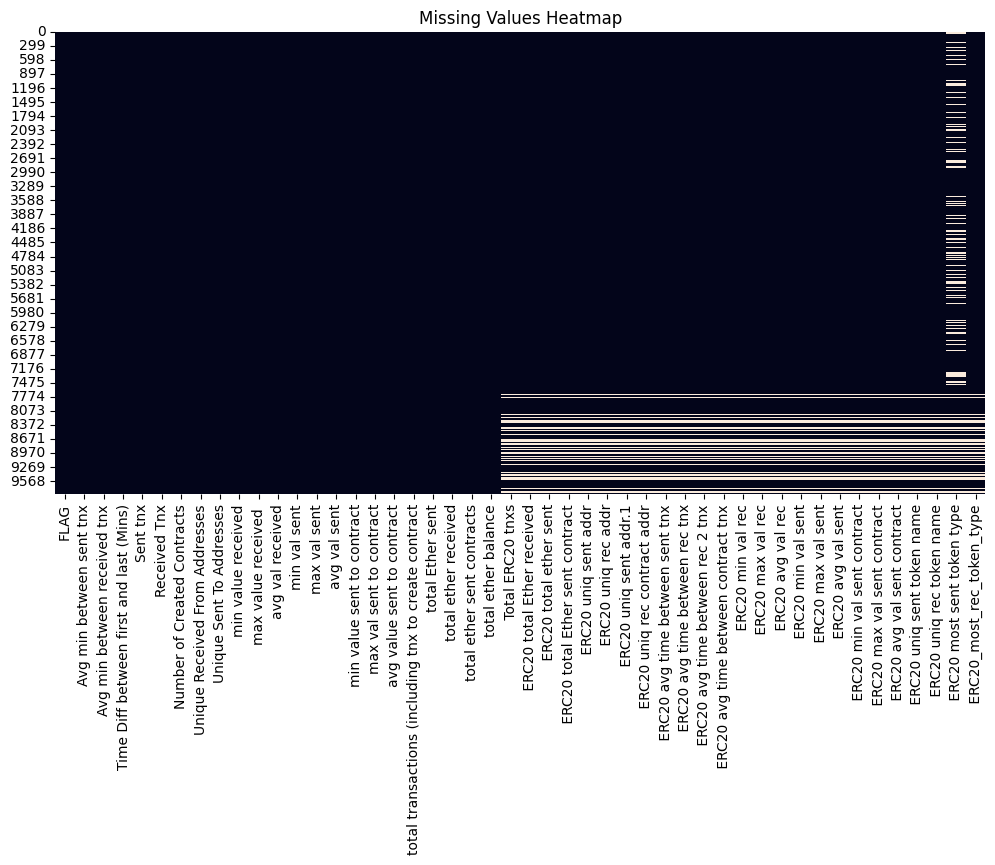

In [24]:
plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(),
            cbar=False)

plt.title('Missing Values Heatmap')

plt.show()

In [25]:
df.isnull().sum().sum()

np.int64(22635)

In [26]:
num_cols = df.select_dtypes(include=['int64','float64']).columns

cat_cols = df.select_dtypes(include=['object']).columns

print("Numerical Columns:", len(num_cols))
print("Categorical Columns:", len(cat_cols))

cat_cols

Numerical Columns: 46
Categorical Columns: 2


Index([' ERC20 most sent token type', ' ERC20_most_rec_token_type'], dtype='object')

In [27]:
df[num_cols] = df[num_cols].fillna(0)

In [28]:
df[num_cols].isnull().sum().sum()

np.int64(0)

In [29]:
df[cat_cols] = df[cat_cols].fillna('Unknown')

In [30]:
df[cat_cols].isnull().sum()

,0
ERC20 most sent token type,0
ERC20_most_rec_token_type,0


In [31]:
from sklearn.preprocessing import LabelEncoder

le1 = LabelEncoder()
le2 = LabelEncoder()

df[' ERC20 most sent token type'] = le1.fit_transform(
    df[' ERC20 most sent token type']
)

df[' ERC20_most_rec_token_type'] = le2.fit_transform(
    df[' ERC20_most_rec_token_type']
)

In [32]:
df.head()

,FLAG,Avg min between sent tnx,Avg min between received tnx,Time Diff between first and last (Mins),Sent tnx,Received Tnx,Number of Created Contracts,Unique Received From Addresses,Unique Sent To Addresses,min value received,...,ERC20 min val sent,ERC20 max val sent,ERC20 avg val sent,ERC20 min val sent contract,ERC20 max val sent contract,ERC20 avg val sent contract,ERC20 uniq sent token name,ERC20 uniq rec token name,ERC20 most sent token type,ERC20_most_rec_token_type
0,0,844.26,1093.71,704785.63,721,89,0,40,118,0.000000,...,0.000000,1.683100e+07,271779.920000,0.0,0.0,0.0,39.0,57.0,63,299
1,0,12709.07,2958.44,1218216.73,94,8,0,5,14,0.000000,...,2.260809,2.260809e+00,2.260809,0.0,0.0,0.0,1.0,7.0,154,257
2,0,246194.54,2434.02,516729.30,2,10,0,10,2,0.113119,...,0.000000,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,8.0,270,436
3,0,10219.60,15785.09,397555.90,25,9,0,7,13,0.000000,...,100.000000,9.029231e+03,3804.076893,0.0,0.0,0.0,1.0,11.0,216,436
4,0,36.61,10707.77,382472.42,4598,20,1,7,19,0.000000,...,0.000000,4.500000e+04,13726.659220,0.0,0.0,0.0,6.0,27.0,237,154


In [33]:
df.isnull().sum().sum()

np.int64(0)

In [34]:
X = df.drop('FLAG', axis=1)

y = df['FLAG']

In [35]:
print(X.shape)
print(y.shape)

(9841, 47)
(9841,)


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [37]:
print(X_train.shape)
print(X_test.shape)

(7872, 47)
(1969, 47)


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [39]:
X_train_scaled.shape

(7872, 47)

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [42]:
rf_acc = accuracy_score(y_test, rf_pred)

rf_precision = precision_score(y_test, rf_pred)

rf_recall = recall_score(y_test, rf_pred)

rf_f1 = f1_score(y_test, rf_pred)

print("Accuracy:", rf_acc)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

Accuracy: 0.9908583037074657
Precision: 1.0
Recall: 0.9587155963302753
F1 Score: 0.9789227166276346


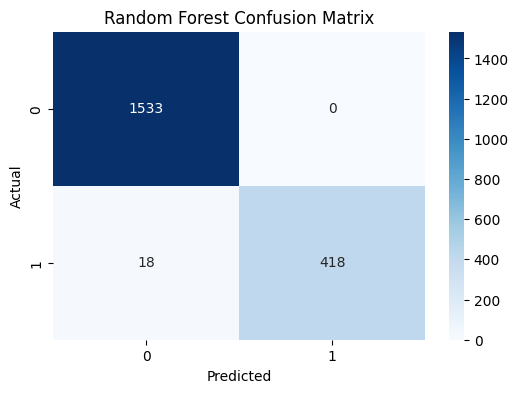

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [44]:
from sklearn.svm import SVC

svm = SVC(
    kernel='rbf',
    random_state=42
)

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

In [45]:
svm_acc = accuracy_score(y_test, svm_pred)

svm_precision = precision_score(y_test, svm_pred)

svm_recall = recall_score(y_test, svm_pred)

svm_f1 = f1_score(y_test, svm_pred)

print("Accuracy:", svm_acc)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)

Accuracy: 0.9558151345860844
Precision: 0.8993135011441648
Recall: 0.9013761467889908
F1 Score: 0.9003436426116839


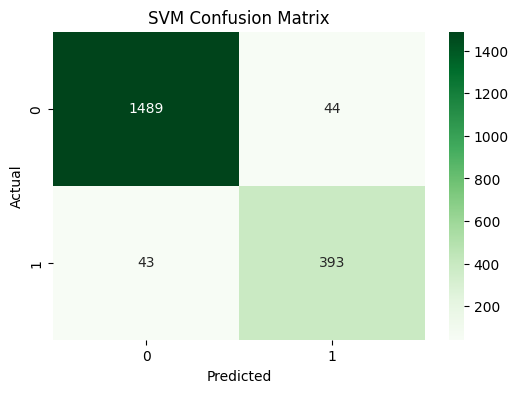

In [46]:
cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [47]:
!pip install xgboost

In [48]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

In [49]:
xgb_acc = accuracy_score(y_test, xgb_pred)

xgb_precision = precision_score(y_test, xgb_pred)

xgb_recall = recall_score(y_test, xgb_pred)

xgb_f1 = f1_score(y_test, xgb_pred)

print("Accuracy:", xgb_acc)
print("Precision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1 Score:", xgb_f1)

Accuracy: 0.9918740477399696
Precision: 0.9929577464788732
Recall: 0.9701834862385321
F1 Score: 0.9814385150812065


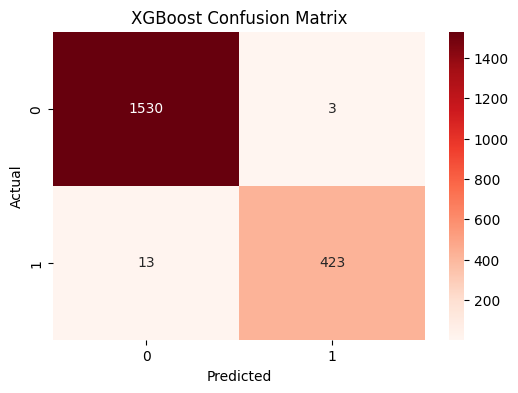

In [50]:
cm = confusion_matrix(y_test, xgb_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds'
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [51]:
import pandas as pd

results = pd.DataFrame({
    'Model': ['Random Forest', 'SVM', 'XGBoost'],
    'Accuracy': [rf_acc, svm_acc, xgb_acc],
    'Precision': [rf_precision, svm_precision, xgb_precision],
    'Recall': [rf_recall, svm_recall, xgb_recall],
    'F1 Score': [rf_f1, svm_f1, xgb_f1]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.990858,1.000000,0.958716,0.978923
1,SVM,0.955815,0.899314,0.901376,0.900344
2,XGBoost,0.991874,0.992958,0.970183,0.981439


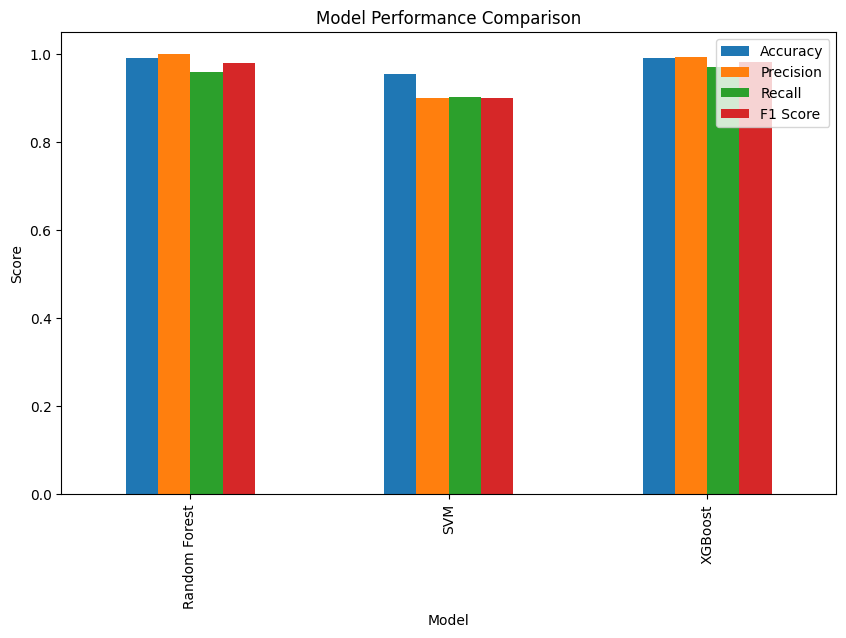

In [52]:
results.set_index('Model')[['Accuracy','Precision','Recall','F1 Score']].plot(
    kind='bar',
    figsize=(10,6)
)

plt.title("Model Performance Comparison")

plt.ylabel("Score")

plt.show()

In [53]:
fraud_probability = xgb.predict_proba(X_test)

fraud_probability[:5]


array([[1.9770861e-04, 9.9980229e-01],
       [9.9998003e-01, 1.9992769e-05],
       [9.9990386e-01, 9.6155949e-05],
       [9.9995822e-01, 4.1776628e-05],
       [9.1520858e-01, 8.4791392e-02]], dtype=float32)

In [54]:
risk_prob = fraud_probability[:,1]

risk_prob[:10]


array([9.9980229e-01, 1.9992769e-05, 9.6155949e-05, 4.1776628e-05,
       8.4791392e-02, 5.4839307e-05, 9.9986458e-01, 1.5959115e-05,
       2.9953549e-02, 1.9992769e-05], dtype=float32)

In [55]:
risk_score = risk_prob * 100

In [56]:
risk_score[:10]

array([9.9980232e+01, 1.9992769e-03, 9.6155945e-03, 4.1776625e-03,
       8.4791393e+00, 5.4839309e-03, 9.9986458e+01, 1.5959115e-03,
       2.9953549e+00, 1.9992769e-03], dtype=float32)

In [57]:
import pandas as pd

risk_category = []

for score in risk_score:

    if score <= 30:
        risk_category.append("Low Risk")

    elif score <= 70:
        risk_category.append("Medium Risk")

    else:
        risk_category.append("High Risk")


In [58]:
risk_df = pd.DataFrame({
    'Actual_Class': y_test.values,
    'Fraud_Probability': risk_prob,
    'Risk_Score': risk_score,
    'Risk_Category': risk_category
})

risk_df.head()


,Actual_Class,Fraud_Probability,Risk_Score,Risk_Category
0,1,0.999802,99.980232,High Risk
1,0,0.000020,0.001999,Low Risk
2,0,0.000096,0.009616,Low Risk
3,0,0.000042,0.004178,Low Risk
4,1,0.084791,8.479139,Low Risk


In [59]:
risk_df['Risk_Category'].value_counts()

,count
Risk_Category,
Low Risk,1537
High Risk,422
Medium Risk,10


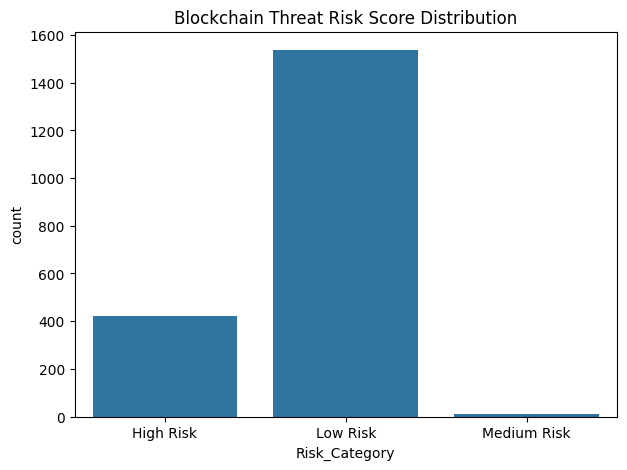

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

sns.countplot(
    x='Risk_Category',
    data=risk_df
)

plt.title("Blockchain Threat Risk Score Distribution")

plt.show()


In [61]:
risk_df['Risk_Score'].describe()

,Risk_Score
count,1969.000000
mean,21.758507
std,40.916233
min,0.000502
25%,0.003199
50%,0.006597
75%,0.623772
max,99.999298


In [62]:
risk_df.sort_values(
    by='Risk_Score',
    ascending=False
).head(20)


,Actual_Class,Fraud_Probability,Risk_Score,Risk_Category
914,1,0.999993,99.999298,High Risk
1904,1,0.999992,99.999168,High Risk
1698,1,0.999991,99.999115,High Risk
548,1,0.999991,99.999115,High Risk
1128,1,0.999991,99.999062,High Risk
638,1,0.999990,99.999031,High Risk
1415,1,0.999990,99.999023,High Risk
961,1,0.999990,99.999008,High Risk
882,1,0.999989,99.998924,High Risk
399,1,0.999989,99.998856,High Risk


In [63]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
})

feature_importance.head()


,Feature,Importance
0,Avg min between sent tnx,0.003024
1,Avg min between received tnx,0.003052
2,Time Diff between first and last (Mins),0.029083
3,Sent tnx,0.004167
4,Received Tnx,0.013736


In [64]:
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(20)


,Feature,Importance
45,ERC20 most sent token type,0.316932
46,ERC20_most_rec_token_type,0.268753
22,Total ERC20 tnxs,0.186467
24,ERC20 total ether sent,0.035860
2,Time Diff between first and last (Mins),0.029083
39,ERC20 avg val sent,0.016623
43,ERC20 uniq sent token name,0.016157
4,Received Tnx,0.013736
17,total transactions (including tnx to create co...,0.012552
6,Unique Received From Addresses,0.012046


In [65]:
top10 = feature_importance.head(10)

top10

,Feature,Importance
45,ERC20 most sent token type,0.316932
46,ERC20_most_rec_token_type,0.268753
22,Total ERC20 tnxs,0.186467
24,ERC20 total ether sent,0.035860
2,Time Diff between first and last (Mins),0.029083
39,ERC20 avg val sent,0.016623
43,ERC20 uniq sent token name,0.016157
4,Received Tnx,0.013736
17,total transactions (including tnx to create co...,0.012552
6,Unique Received From Addresses,0.012046


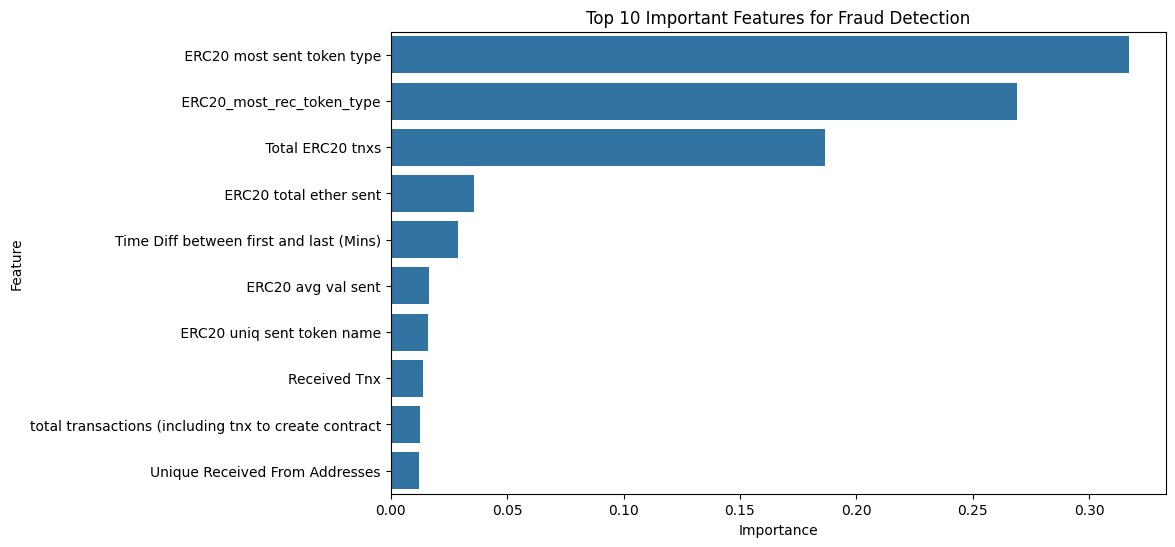

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10,
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features for Fraud Detection")

plt.show()

In [67]:
top10['Contribution (%)'] = (
    top10['Importance'] /
    top10['Importance'].sum()
) * 100

top10


/tmp/ipykernel_3342/182513620.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top10['Contribution (%)'] = (


,Feature,Importance,Contribution (%)
45,ERC20 most sent token type,0.316932,34.896366
46,ERC20_most_rec_token_type,0.268753,29.591537
22,Total ERC20 tnxs,0.186467,20.531263
24,ERC20 total ether sent,0.035860,3.948446
2,Time Diff between first and last (Mins),0.029083,3.202213
39,ERC20 avg val sent,0.016623,1.830278
43,ERC20 uniq sent token name,0.016157,1.778989
4,Received Tnx,0.013736,1.512478
17,total transactions (including tnx to create co...,0.012552,1.382088
6,Unique Received From Addresses,0.012046,1.326336


In [68]:
top10.to_csv(
    'top10_feature_importance.csv',
    index=False
)


In [69]:
top10.to_csv(
    'top10_feature_importance.csv',
    index=False
)

In [70]:
feature_importance.head(20)

,Feature,Importance
45,ERC20 most sent token type,0.316932
46,ERC20_most_rec_token_type,0.268753
22,Total ERC20 tnxs,0.186467
24,ERC20 total ether sent,0.035860
2,Time Diff between first and last (Mins),0.029083
39,ERC20 avg val sent,0.016623
43,ERC20 uniq sent token name,0.016157
4,Received Tnx,0.013736
17,total transactions (including tnx to create co...,0.012552
6,Unique Received From Addresses,0.012046


In [71]:
top10 = top10.copy()

top10['Contribution (%)'] = (
    top10['Importance'] /
    top10['Importance'].sum()
) * 100
